In [1]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
import optuna
import sys
from pathlib import Path
import torch # Torch needs to be installed manually if you want cuda. See installation command on pytorch website
import warnings

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

/home/koyo-ai/miniconda3/envs/homeless/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 987
TRACK = "off_market"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-06-01")    # sales on or after this date are validation
N_TRIALS = 20                             # optuna trials
N_ESTIMATORS = 2000                      # max boosting rounds per trial
EARLY_STOPPING_ROUNDS = 100
K_FOLDS = 5                              # time series cross validation folds
DEBUG = True                             # print MdAPE and MAPE for every fold

In [3]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [4]:
# 'municipality', 'square_feet_x_bedrooms', 'is_apartment_1_x_square_feet', 'bedrooms_x_washrooms', 'bedrooms', 'longitude', 'bedrooms_x_parking', 'is_apartment_1_x_bedrooms', 'is_apartment_1_x_parking', 'latitude', 'parking', 'day', 'year', 'house_style', 'is_apartment_0_x_parking', 'is_apartment_0_x_bedrooms', 'month'

is_apartment_0_x_square_feet    0.105196
lot_front                       0.024596
community                       0.018983
square_feet_x_washrooms         0.018398
washrooms                       0.017611
house_type                      0.016939
square_feet                     0.015868
is_apartment_1_x_washrooms      0.015063
is_apartment                    0.012654
square_feet_x_parking           0.007868
washrooms_x_parking             0.006500
lot_depth                       0.006389
municipality                    0.004878
square_feet_x_bedrooms          0.004408
is_apartment_1_x_square_feet    0.003503
bedrooms_x_washrooms            0.003196
bedrooms                        0.002718
longitude                       0.002580
bedrooms_x_parking              0.002407
is_apartment_1_x_bedrooms       0.002226
is_apartment_1_x_parking        0.002136
latitude                        0.002105
parking                         0.002061
day                             0.002048
year                            0.001828
house_style                     0.001822
is_apartment_0_x_parking        0.001744
is_apartment_0_x_bedrooms       0.001690
month                           0.001644
dtype: float32

In [5]:
from baseline_features import off_market_features, list_aware_features

make_features = off_market_features if TRACK == "off_market" else list_aware_features

good_features = ['is_apartment_x_washrooms_0', 'is_apartment_x_square_feet_0', 'lot_front', 'community', 'square_feet_x_washrooms', 'washrooms', 'house_type', 
                 'square_feet', 'is_apartment_x_washrooms_1', 'is_apartment', 'square_feet_x_parking', 'washrooms_x_parking', 'lot_depth', 'municipality', 'square_feet_x_bedrooms', 'is_apartment_x_square_feet_1', 'bedrooms_x_washrooms', 'bedrooms', 'longitude', 'bedrooms_x_parking', 'is_apartment_x_bedrooms_1', 'is_apartment_x_parking_1', 'latitude', 'parking', 'day']

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

X_train = make_features(train)
X_train = X_train[good_features]
X_val = make_features(val)
X_val = X_val[good_features]

y_train = np.log(train["sold_price"])
y_val = np.log(val["sold_price"])

print(f"Features: {X_train.columns.tolist()}")
print(f"train: {len(train):,} sales up to {VAL_START.date()}")
print(f"val:   {len(val):,} sales from {VAL_START.date()}")

Features: ['is_apartment_x_washrooms_0', 'is_apartment_x_square_feet_0', 'lot_front', 'community', 'square_feet_x_washrooms', 'washrooms', 'house_type', 'square_feet', 'is_apartment_x_washrooms_1', 'is_apartment', 'square_feet_x_parking', 'washrooms_x_parking', 'lot_depth', 'municipality', 'square_feet_x_bedrooms', 'is_apartment_x_square_feet_1', 'bedrooms_x_washrooms', 'bedrooms', 'longitude', 'bedrooms_x_parking', 'is_apartment_x_bedrooms_1', 'is_apartment_x_parking_1', 'latitude', 'parking', 'day']
train: 127,762 sales up to 2025-06-01
val:   22,238 sales from 2025-06-01


In [6]:
# TODO: Try different losses
def mdape(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

loss = mdape

In [7]:
from sklearn.model_selection import TimeSeriesSplit


def cross_val(X, y, params, K=5, debug=False, validation_loss=mdape):
    """Walk-forward K-fold: each fold trains on every row before its validation block.
    X and y must be sorted by time (listings is sorted by date_sold).
    Returns the mean validation loss over the folds."""
    mdape_scores = [] 
    mape_scores = []
    for fold, (train_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=K).split(X), start=1):
        X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]

        model = XGBRegressor(**params, device=DEVICE, n_estimators=N_ESTIMATORS,
                             early_stopping_rounds=EARLY_STOPPING_ROUNDS, random_state=SEED)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        pred = model.predict(X_va)
        mdape_scores.append(validation_loss(y_va, pred))

        mape_scores.append(np.mean(100 * np.abs(np.exp(pred) / np.exp(y_va) - 1)))

        if debug:
            error = 100 * np.abs(np.exp(pred) / np.exp(y_va) - 1)
            print(f"fold {fold}: train {len(train_idx):,}  val {len(val_idx):,}  "
                  f"MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%", flush=True)

    print(f"mean MdAPE {np.mean(mdape_scores):.2f}%  mean MAPE {np.mean(mape_scores):.2f}%", flush=True)
    return np.mean(mdape_scores)

In [8]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
        "max_depth": trial.suggest_int("max_depth", 3, 13),
        "subsample": trial.suggest_float("subsample", 0.1, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
        "max_bin": trial.suggest_int("max_bin", 256, 2048),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 0.1, step=0.01),
        "lambda": trial.suggest_float("lambda", 1e-3, 10.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-3, 10.0, log=True),
        "max_delta_step": trial.suggest_int("max_delta_step", 1, 10),
        "enable_categorical": True,
    }
    score = cross_val(X_train, y_train, params, K=K_FOLDS, debug=DEBUG, validation_loss=loss)
    return score

In [9]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name="VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!")
study.optimize(objective, n_trials=N_TRIALS)

print("best val MdAPE:", round(study.best_value, 2))
print("best params:", study.best_params)

[I 2026-10-15 19:21:46,030] A new study created in memory with name: VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!


fold 1: train 21,297  val 21,293  MdAPE 10.29%  MAPE 12.73%
fold 2: train 42,590  val 21,293  MdAPE 10.65%  MAPE 13.29%
fold 3: train 63,883  val 21,293  MdAPE 10.29%  MAPE 12.73%
fold 4: train 85,176  val 21,293  MdAPE 10.13%  MAPE 13.08%
fold 5: train 106,469  val 21,293  MdAPE 10.29%  MAPE 13.34%
mean MdAPE 10.33%  mean MAPE 13.03%


[I 2026-10-15 19:22:02,645] Trial 0 finished with value: 10.330173656166062 and parameters: {'learning_rate': 0.05, 'max_depth': 7, 'subsample': 0.9, 'colsample_bytree': 0.5, 'max_bin': 1778, 'min_child_weight': 10, 'gamma': 0.1, 'lambda': 7.103714746188992, 'alpha': 0.0013187949354214168, 'max_delta_step': 1}. Best is trial 0 with value: 10.330173656166062.


fold 1: train 21,297  val 21,293  MdAPE 10.67%  MAPE 13.07%
fold 2: train 42,590  val 21,293  MdAPE 11.01%  MAPE 13.72%
fold 3: train 63,883  val 21,293  MdAPE 11.04%  MAPE 13.37%
fold 4: train 85,176  val 21,293  MdAPE 10.32%  MAPE 13.27%
fold 5: train 106,469  val 21,293  MdAPE 10.50%  MAPE 13.52%
mean MdAPE 10.71%  mean MAPE 13.39%


[I 2026-10-15 19:22:09,426] Trial 1 finished with value: 10.708819198284719 and parameters: {'learning_rate': 0.09, 'max_depth': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'max_bin': 808, 'min_child_weight': 3, 'gamma': 0.08, 'lambda': 4.791227993546376, 'alpha': 0.0058203973119644765, 'max_delta_step': 9}. Best is trial 0 with value: 10.330173656166062.


...

fold 1: train 21,297  val 21,293  MdAPE 9.89%  MAPE 12.60%
fold 2: train 42,590  val 21,293  MdAPE 10.03%  MAPE 12.79%
fold 3: train 63,883  val 21,293  MdAPE 9.41%  MAPE 11.99%
fold 4: train 85,176  val 21,293  MdAPE 9.88%  MAPE 13.04%
fold 5: train 106,469  val 21,293  MdAPE 10.20%  MAPE 13.44%
mean MdAPE 9.88%  mean MAPE 12.77%


[I 2026-10-15 19:38:39,067] Trial 18 finished with value: 9.880909212238171 and parameters: {'learning_rate': 0.02, 'max_depth': 13, 'subsample': 1.0, 'colsample_bytree': 0.30000000000000004, 'max_bin': 1885, 'min_child_weight': 9, 'gamma': 0.0, 'lambda': 0.9336624248120213, 'alpha': 0.013025218435064951, 'max_delta_step': 1}. Best is trial 14 with value: 9.875106594494822.


fold 1: train 21,297  val 21,293  MdAPE 10.21%  MAPE 12.82%
fold 2: train 42,590  val 21,293  MdAPE 10.38%  MAPE 13.12%
fold 3: train 63,883  val 21,293  MdAPE 10.05%  MAPE 12.54%
fold 4: train 85,176  val 21,293  MdAPE 9.83%  MAPE 12.83%
fold 5: train 106,469  val 21,293  MdAPE 10.23%  MAPE 13.37%
mean MdAPE 10.14%  mean MAPE 12.94%


[I 2026-10-15 19:40:02,344] Trial 19 finished with value: 10.13864519301452 and parameters: {'learning_rate': 0.04, 'max_depth': 13, 'subsample': 1.0, 'colsample_bytree': 0.5, 'max_bin': 1553, 'min_child_weight': 9, 'gamma': 0.01, 'lambda': 0.2997417115407888, 'alpha': 0.0016902374113569574, 'max_delta_step': 2}. Best is trial 14 with value: 9.875106594494822.


best val MdAPE: 9.88
best params: {'learning_rate': 0.04, 'max_depth': 13, 'subsample': 1.0, 'colsample_bytree': 0.5, 'max_bin': 1571, 'min_child_weight': 10, 'gamma': 0.0, 'lambda': 1.0710790835442294, 'alpha': 0.03917756821506849, 'max_delta_step': 2}


In [10]:
from optuna.importance import get_param_importances

importance = get_param_importances(study)

for param, score in importance.items():
    print(f"{param}: {score:.4f}")

lambda: 0.2726
max_depth: 0.2577
gamma: 0.1936
subsample: 0.1311
learning_rate: 0.0603
max_delta_step: 0.0270
min_child_weight: 0.0239
alpha: 0.0198
colsample_bytree: 0.0127
max_bin: 0.0013


In [11]:
model = XGBRegressor(**study.best_params,
                     enable_categorical=True,
                     device=DEVICE,
                     early_stopping_rounds=EARLY_STOPPING_ROUNDS,
                     n_estimators=N_ESTIMATORS,
                     random_state=SEED)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

predicted = np.exp(model.predict(X_val))
error = 100 * np.abs(predicted / val["sold_price"] - 1)
print(f"{TRACK}  MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%")

off_market  MdAPE 10.09%  MAPE 13.30%


In [12]:
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(feature_importances)

is_apartment_x_washrooms_0      0.604599
house_type                      0.105198
is_apartment_x_square_feet_0    0.093496
washrooms                       0.065791
community                       0.021898
square_feet                     0.017594
lot_depth                       0.016556
square_feet_x_washrooms         0.015639
is_apartment_x_washrooms_1      0.007903
washrooms_x_parking             0.006652
lot_front                       0.004826
is_apartment_x_square_feet_1    0.004578
square_feet_x_parking           0.004209
municipality                    0.004048
bedrooms_x_washrooms            0.003358
is_apartment_x_bedrooms_1       0.003002
longitude                       0.002913
latitude                        0.002808
square_feet_x_bedrooms          0.002661
parking                         0.002548
bedrooms_x_parking              0.002233
day                             0.002120
is_apartment_x_parking_1        0.002119
is_apartment                    0.001723
bedrooms        

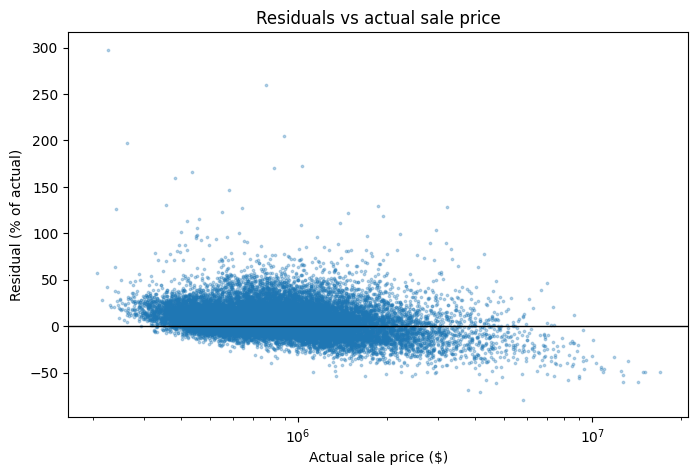

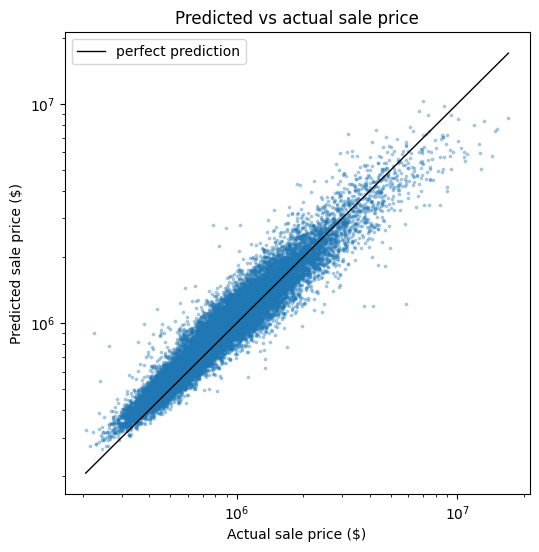

In [13]:
import diagnostics

actual = val["sold_price"]

diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.plot_predicted_vs_actual(actual, predicted)

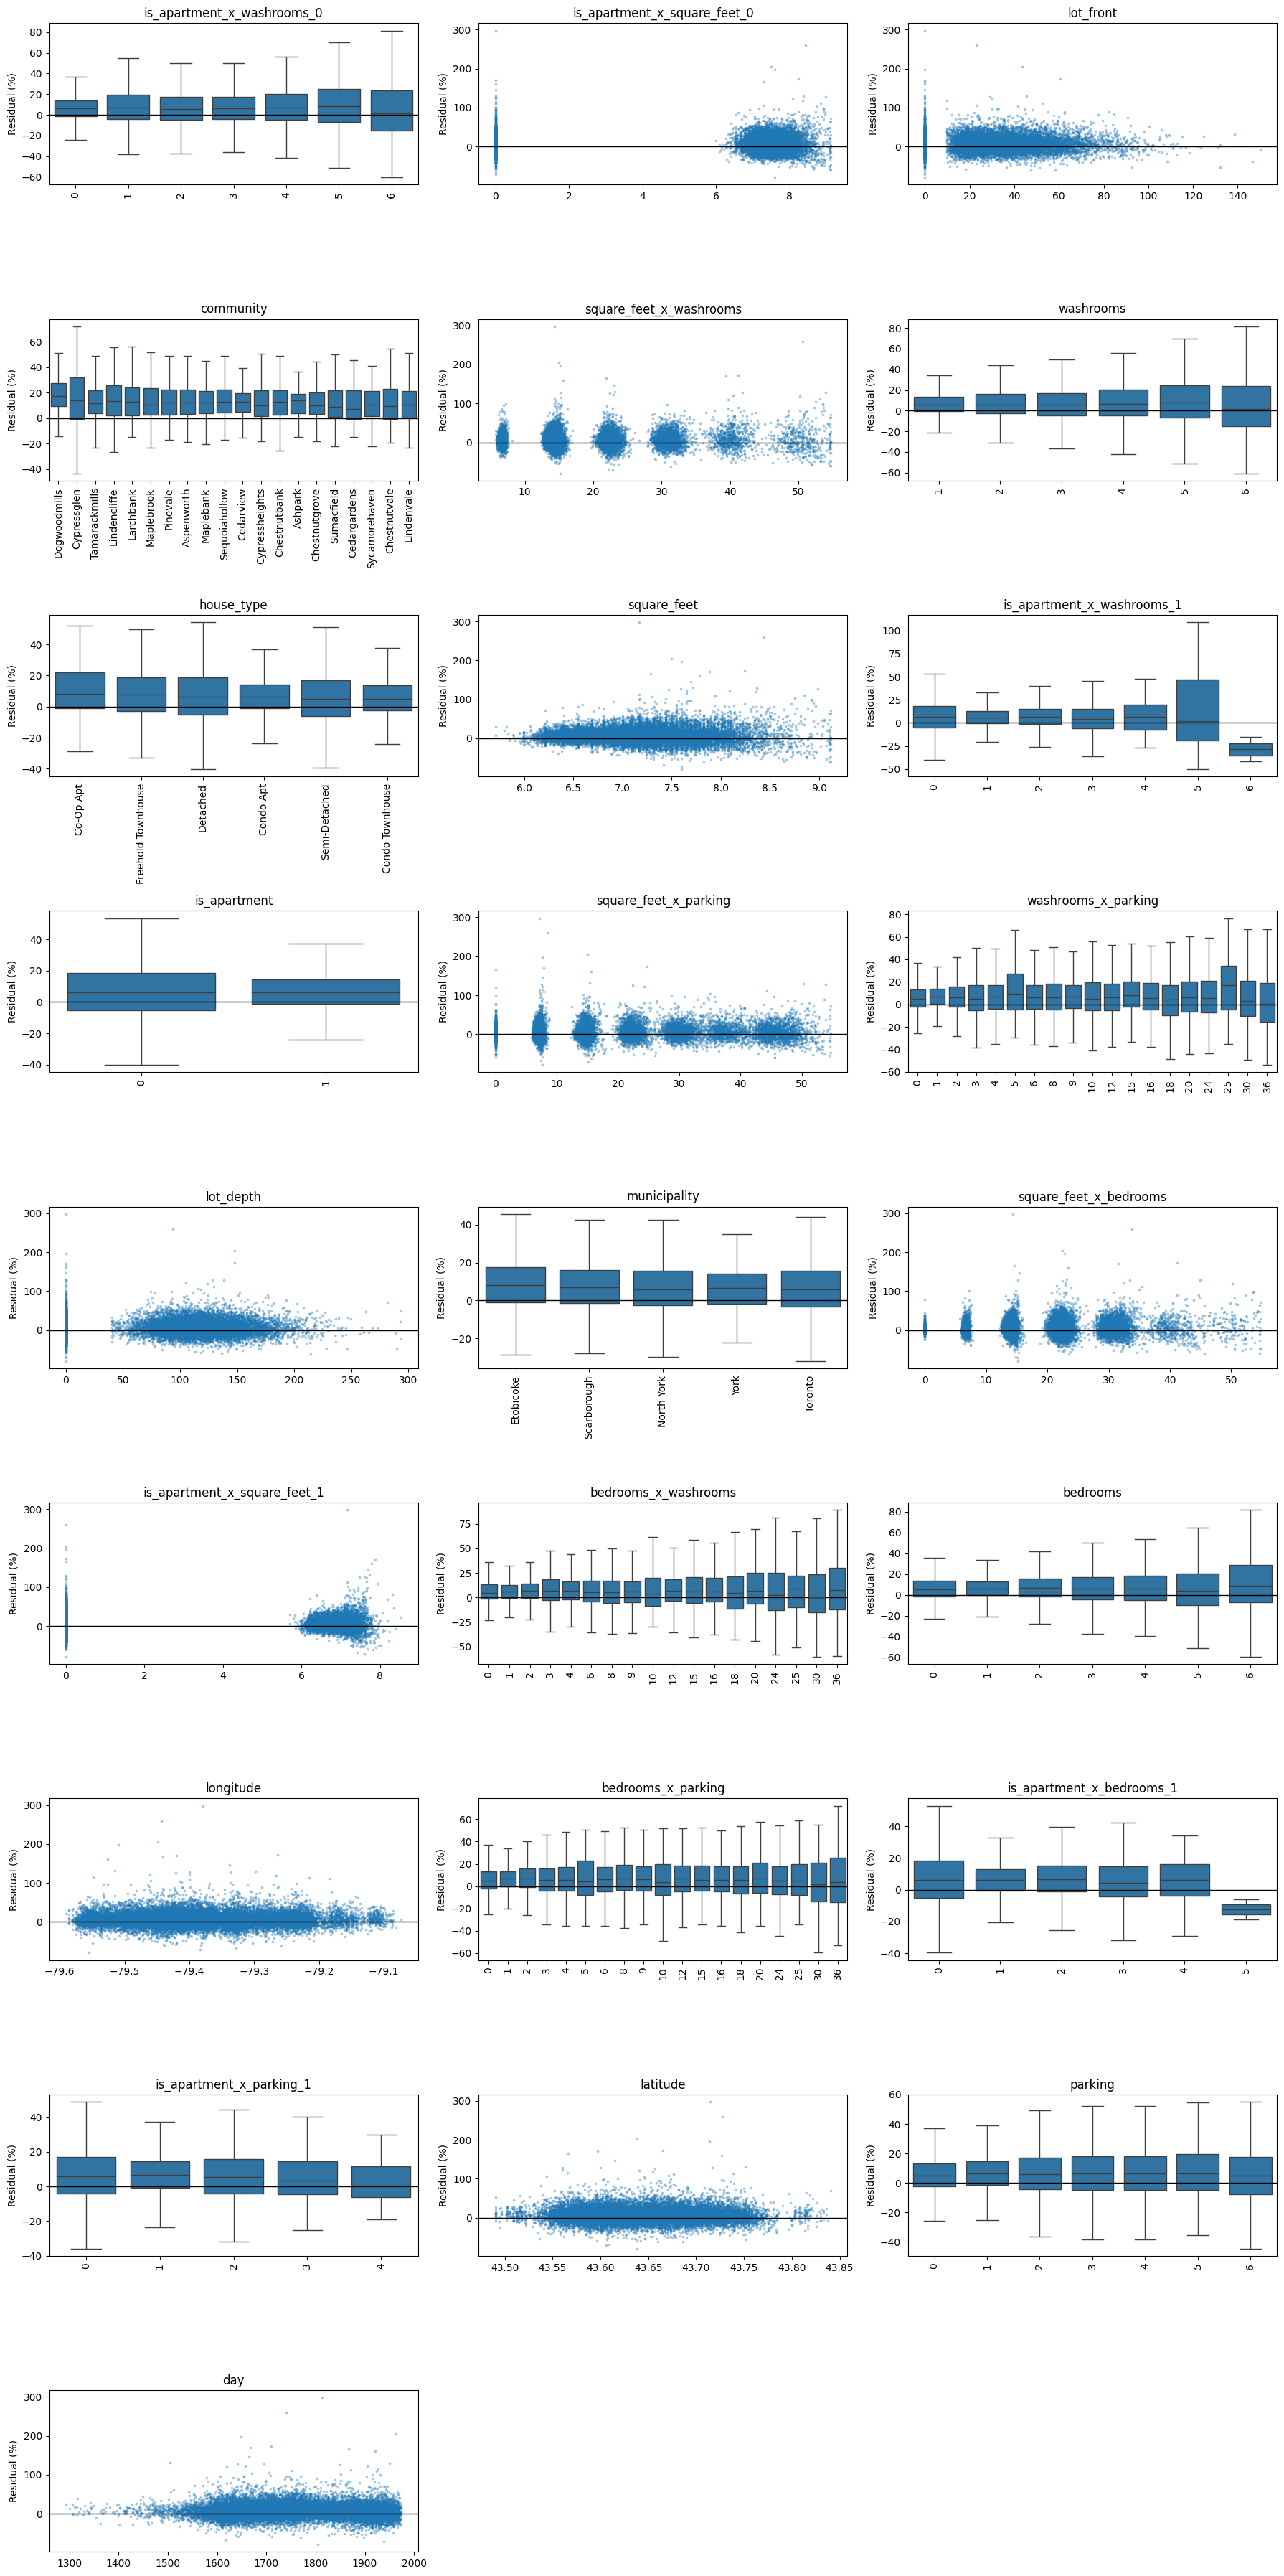

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_residuals_by_feature(X, actual, predicted, max_categories=20, n_cols=3):
    """One panel per column of X: a scatter plot for continuous columns and a box plot
    for categorical ones. Numeric columns with at most max_categories distinct values
    (bedrooms, month, ...) count as categorical. Columns with more categories than that
    show only their max_categories most common values."""
    residual = percent_error(actual, predicted)
    n_rows = int(np.ceil(len(X.columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)

    for ax, column in zip(axes.flat, X.columns):
        values = X[column].to_numpy()
        is_numeric = pd.api.types.is_numeric_dtype(X[column])
        if is_numeric and X[column].nunique() > max_categories:
            ax.scatter(values, residual, s=3, alpha=0.3)
        else:
            if is_numeric:
                order = sorted(X[column].value_counts().index[:max_categories])
            else:
                order = (
                    pd.DataFrame({"category": X[column], "residual": residual})
                    .groupby("category")["residual"]
                    .mean()
                    .sort_values(ascending=False)
                    .head(max_categories)
                    .index
                    .tolist()
                )
            sns.boxplot(x=values, y=residual, order=order, showfliers=False, ax=ax)
            ax.tick_params(axis="x", rotation=90)
        ax.axhline(0, color="black", linewidth=1)
        ax.set(title=column, xlabel="", ylabel="Residual (%)")

    for ax in axes.flat[len(X.columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

def percent_error(actual, predicted):
    return 100 * (np.asarray(predicted) / np.asarray(actual) - 1)

plot_residuals_by_feature(X_val, actual, predicted)

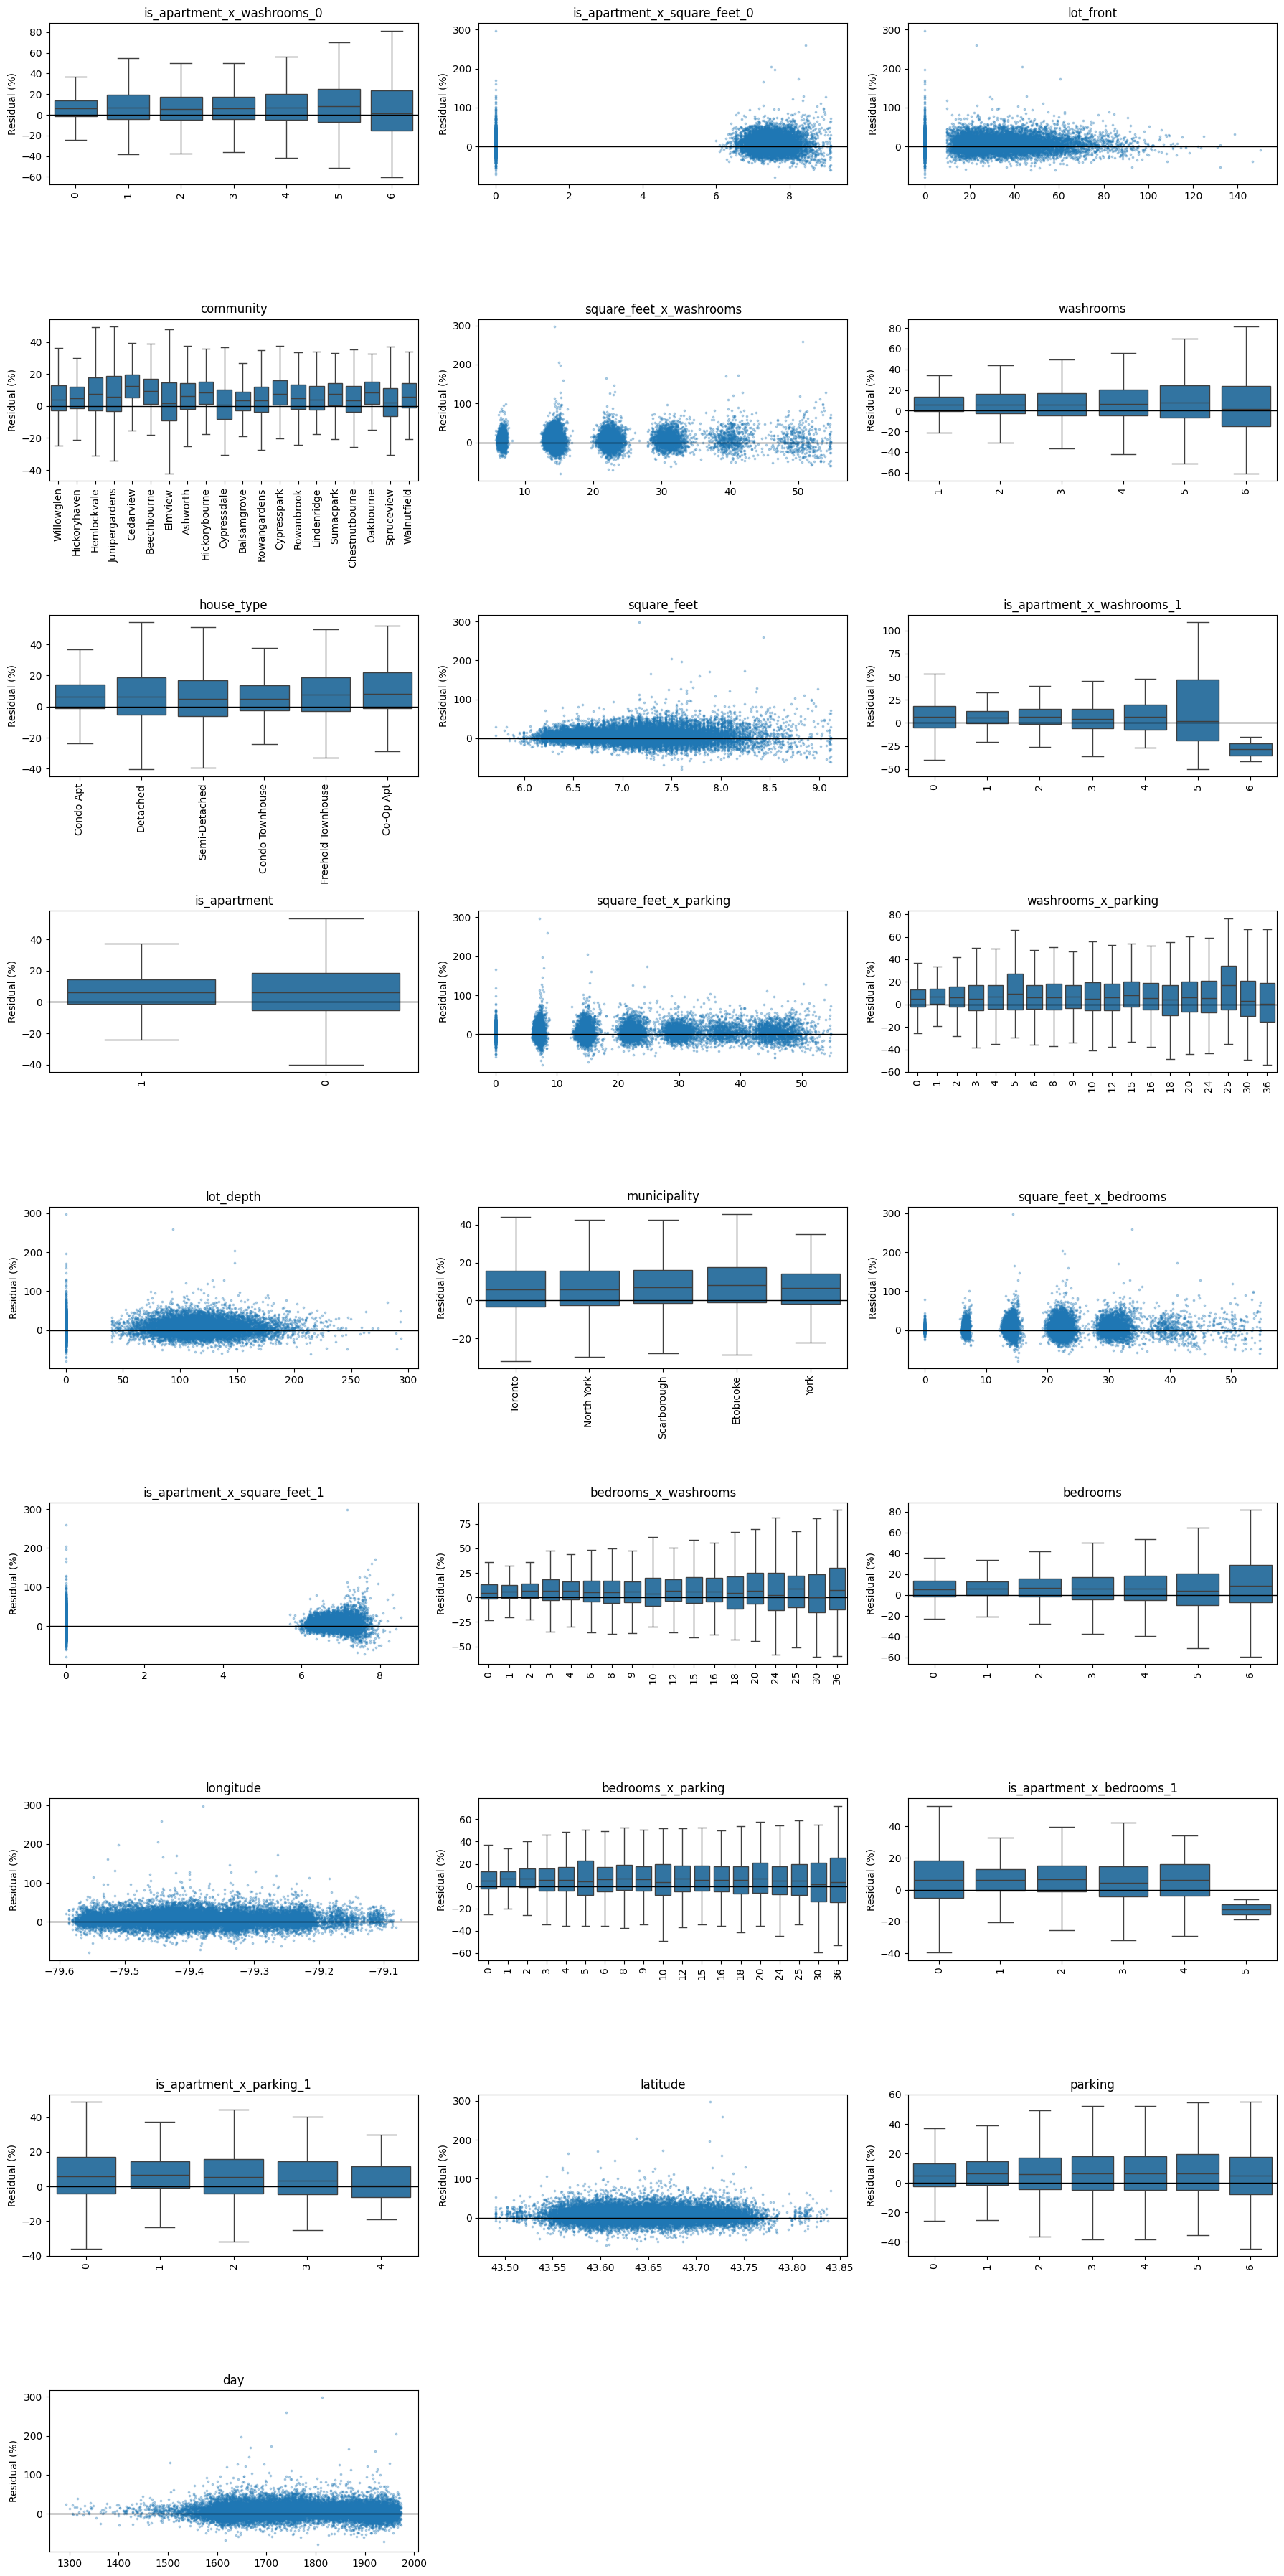

In [14]:
diagnostics.plot_residuals_by_feature(X_val, actual, predicted)